Bazowe N = 13
Wektor x_mu: [10  5  6  6  2  4  3  4  5  0  0  0  0]

Macierz K (13x13):
[[  0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   1   2   3   4   5   6   7   8   9  10  11  12]
 [  0   2   4   6   8  10  12  14  16  18  20  22  24]
 [  0   3   6   9  12  15  18  21  24  27  30  33  36]
 [  0   4   8  12  16  20  24  28  32  36  40  44  48]
 [  0   5  10  15  20  25  30  35  40  45  50  55  60]
 [  0   6  12  18  24  30  36  42  48  54  60  66  72]
 [  0   7  14  21  28  35  42  49  56  63  70  77  84]
 [  0   8  16  24  32  40  48  56  64  72  80  88  96]
 [  0   9  18  27  36  45  54  63  72  81  90  99 108]
 [  0  10  20  30  40  50  60  70  80  90 100 110 120]
 [  0  11  22  33  44  55  66  77  88  99 110 121 132]
 [  0  12  24  36  48  60  72  84  96 108 120 132 144]]

Część rzeczywista macierzy W (zaokrąglona do 2 miejsc po przecinku):
[[ 1.    1.    1.    1.    1.    1.    1.    1.    1.    1.    1.    1.
   1.  ]
 [ 1.    0.89  0.57  0.12 -0.35 -0.75 -0.97 -

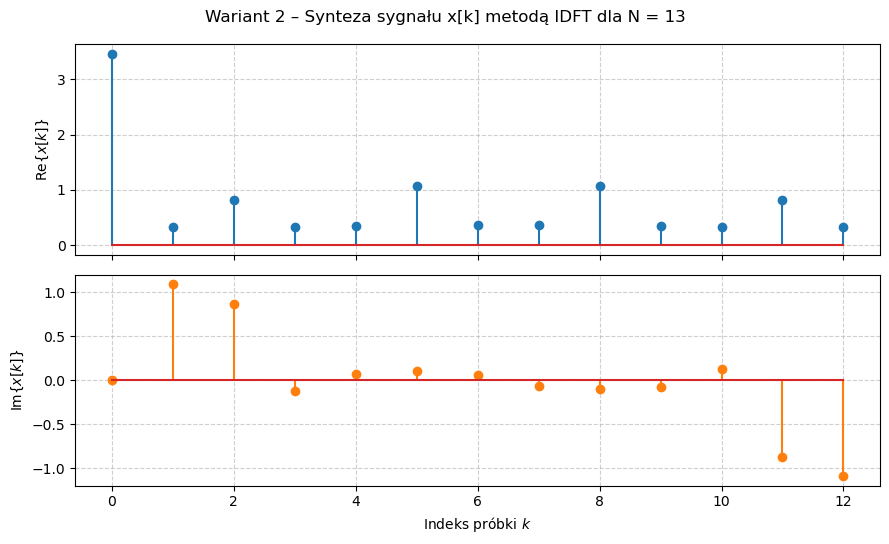

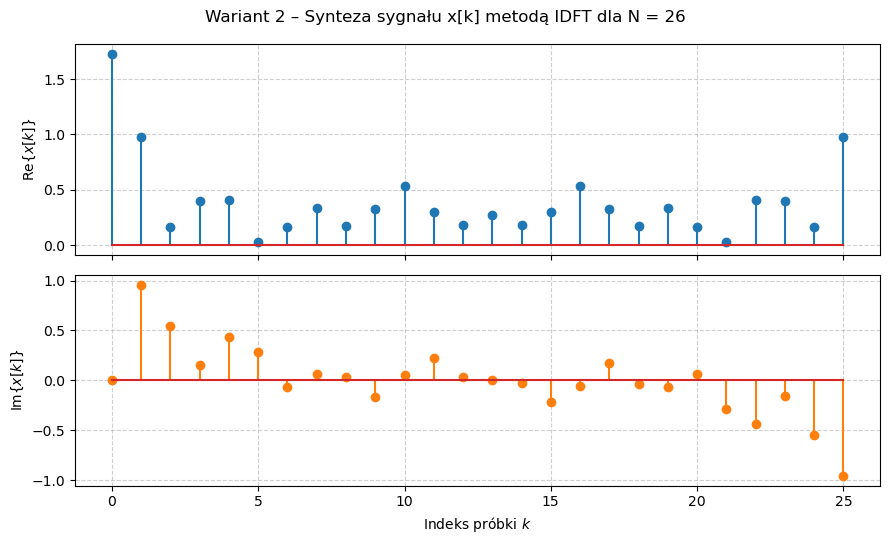

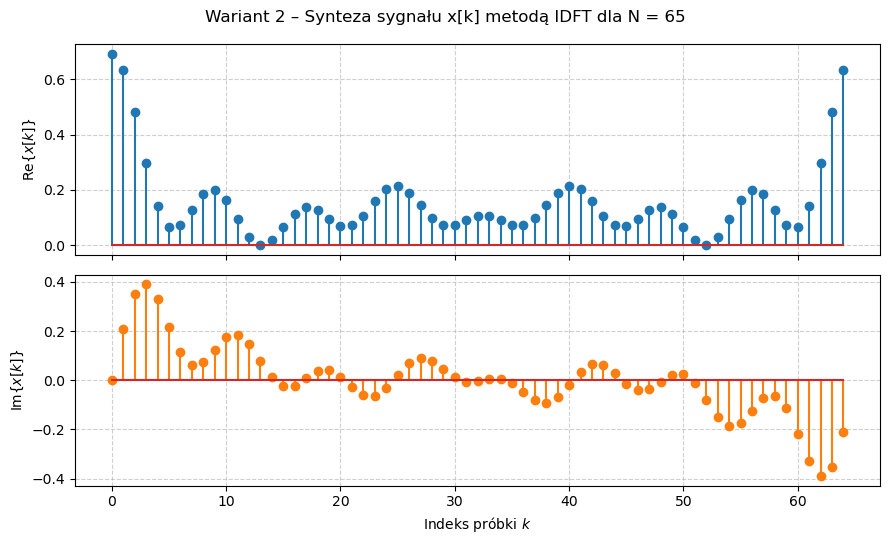

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import warnings

warnings.filterwarnings('ignore')

# Wektor widma dla Wariantu 2 (bazowa długość N = 13)
x_mu_base = np.array([10, 5, 6, 6, 2, 4, 3, 4, 5, 0, 0, 0, 0], dtype=complex)
N_base = len(x_mu_base)


def idft_matrix_synthesis(x_mu_in, N):
  """Synteza sygnału x[k] za pomocą IDFT w notacji macierzowej."""
  if N < len(x_mu_in):
    raise ValueError('N nie może być mniejsze niż długość bazowego wektora!')

  # Uzupełnienie zerami (zero-padding) do długości N
  x_mu = np.pad(x_mu_in, (0, N - len(x_mu_in)), mode='constant')

  # Wektory indeksów k (kolumna) oraz mu (wiersz)
  k = np.arange(N).reshape((N, 1))
  mu = np.arange(N).reshape((1, N))

  # Macierz indeksów K = k * mu^T
  K = k @ mu

  # Macierz Fouriera W (twiddle factors: exp(-j * 2 * pi * k * mu / N))
  # oraz macierz odwrotna/sprzężona dla syntezy IDFT: exp(+j * 2 * pi * k * mu / N)
  W = np.exp(-1j * 2 * np.pi * K / N)
  W_idft = np.exp(+1j * 2 * np.pi * K / N)

  # Synteza sygnału w dziedzinie czasu: x = (1/N) * W_idft * x_mu
  x = (1.0 / N) * (W_idft @ x_mu)

  return x, K, W, W_idft, x_mu


# 1. Obliczenia dla bazowego N = 13
x_13, K_13, W_13, W_idft_13, x_mu_13 = idft_matrix_synthesis(x_mu_base, N_base)

print(f'Bazowe N = {N_base}')
print('Wektor x_mu:', np.real(x_mu_13).astype(int))
print('\nMacierz K (13x13):')
print(K_13)

print('\nCzęść rzeczywista macierzy W (zaokrąglona do 2 miejsc po przecinku):')
print(np.round(np.real(W_13), 2))

print('\nCzęść urojona macierzy W (zaokrąglona do 2 miejsc po przecinku):')
print(np.round(np.imag(W_13), 2))

print('\nZsyntetyzowany sygnał x[k] dla N = 13:')
for idx, val in enumerate(x_13):
  print(f'k={idx:2d}: {val.real:+.4f} {val.imag:+.4f}j')

# 2. Porównanie dla różnych wartości N (N = 13, 26, 65)
N_list = [13, 26, 65]

for N in N_list:
  x, _, _, _, _ = idft_matrix_synthesis(x_mu_base, N)
  n_idx = np.arange(N)

  fig, axes = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True)
  fig.suptitle(
      f'Wariant 2 – Synteza sygnału x[k] metodą IDFT dla N = {N}', fontsize=12
  )

  markerline0, stemlines0, baseline0 = axes[0].stem(n_idx, np.real(x))
  axes[0].set_ylabel(r'$\mathrm{Re}\{x[k]\}$')
  axes[0].grid(True, linestyle='--', alpha=0.6)

  markerline1, stemlines1, baseline1 = axes[1].stem(
      n_idx, np.imag(x), linefmt='C1-', markerfmt='C1o'
  )
  axes[1].set_ylabel(r'$\mathrm{Im}\{x[k]\}$')
  axes[1].set_xlabel('Indeks próbki $k$')
  axes[1].grid(True, linestyle='--', alpha=0.6)

  plt.tight_layout()
  plt.savefig(f'sygnal_N_{N}.png', dpi=200)
  plt.show()